In [2]:
import seaborn as sns
import pandas as pd 
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", palette="muted")

df = pd.read_parquet('../data/application_optimized.parquet')
df.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: category(16), float32(64), float64(1), int16(2), int32(2), int8(37)
memory usage: 96.5 MB


TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


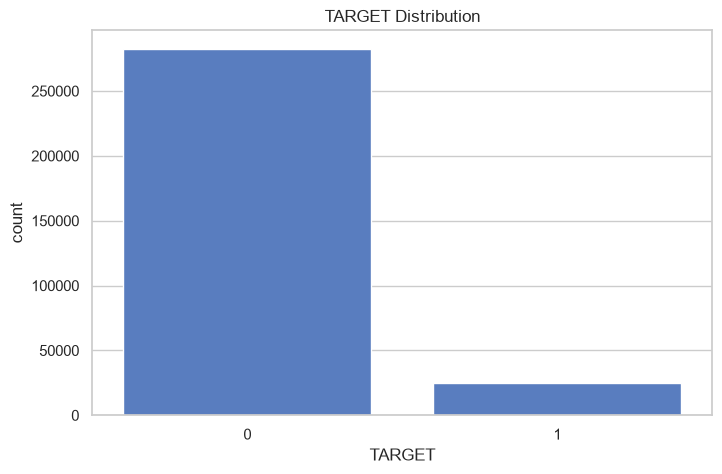

In [3]:
target_dist = df['TARGET'].value_counts(normalize = True) 
print(target_dist)
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='TARGET')
plt.title('TARGET Distribution')
plt.show()

элементов одного класса в 11 раз больше второго
accuracy будет бесполезна при анализе

<Axes: ylabel='None'>

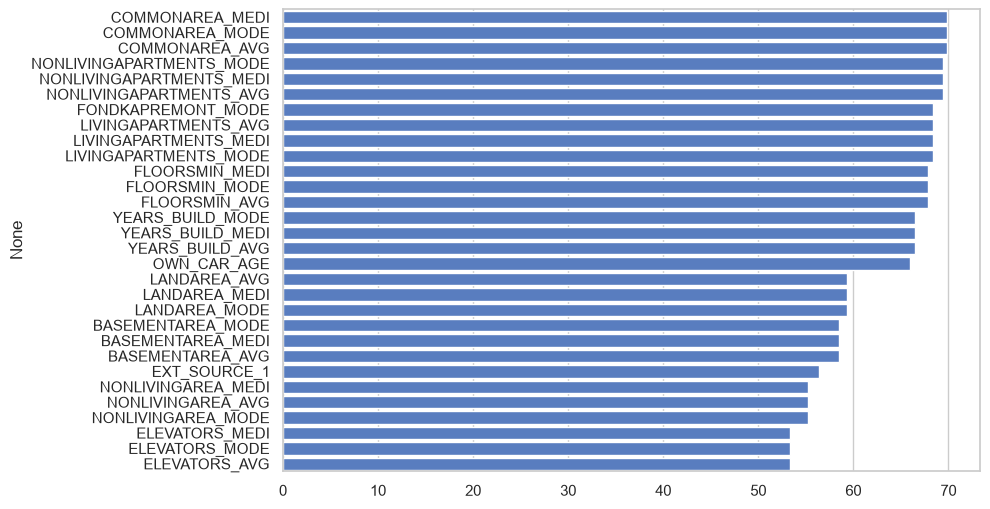

In [5]:
missing_data = df.isna().mean()* 100
missing_data =missing_data[missing_data > 0].sort_values(ascending = False)
plt.figure(figsize =(9,6))
sns.barplot(x=missing_data.head(30).values, y=missing_data.head(30).index)



 около 15 колонок,в которых около 70% пустых значений

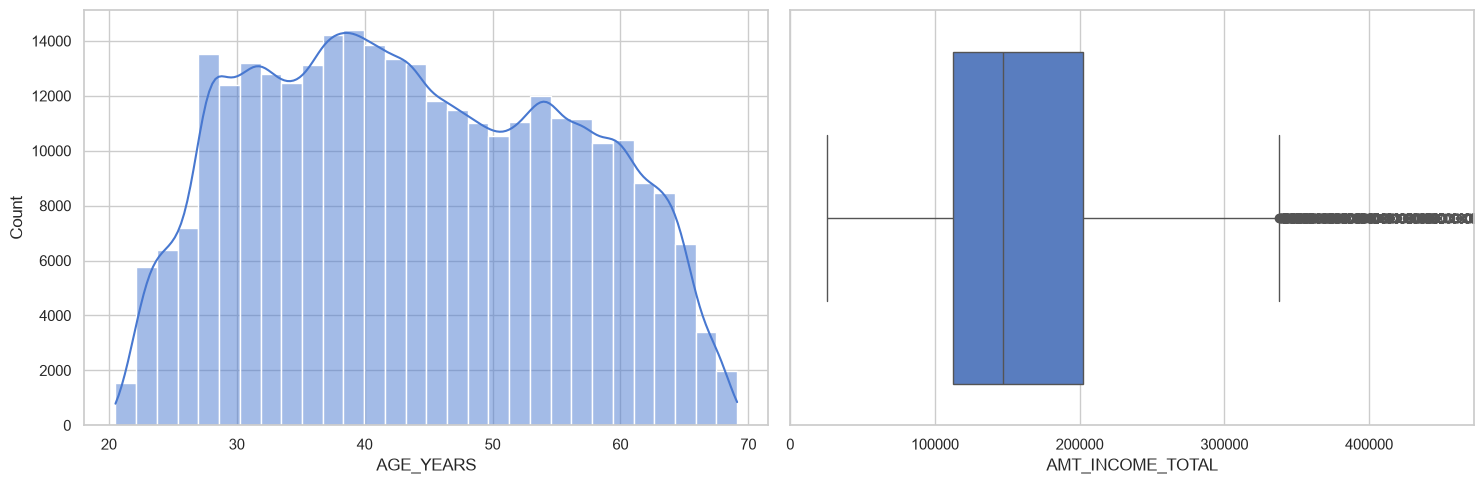

In [3]:
df['AGE_YEARS'] = df['DAYS_BIRTH'] / -365
fig,axes = plt.subplots(1,2,figsize=(15,5))#создали области для двух графиков
sns.histplot(data = df,x ='AGE_YEARS',bins = 30,kde=True,ax=axes[0])
sns.boxplot(data=df,x='AMT_INCOME_TOTAL', ax=axes[1])
axes[1].set_xlim(0, df['AMT_INCOME_TOTAL'].quantile(0.99))#ось бы сжалась из-за выброса и все значения слева слиплись
plt.tight_layout()#чтобы эти графики не налезали друг на друга

Гистограмма
основная масса клиентов 26-60 лет

Ящик с усами
у 50% клиентов доход 110к-200к
медианный доход 150к
Распределение имеет тяжелый правый хвост

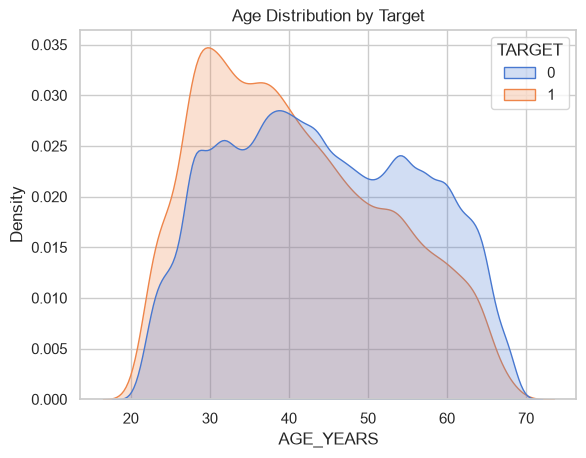

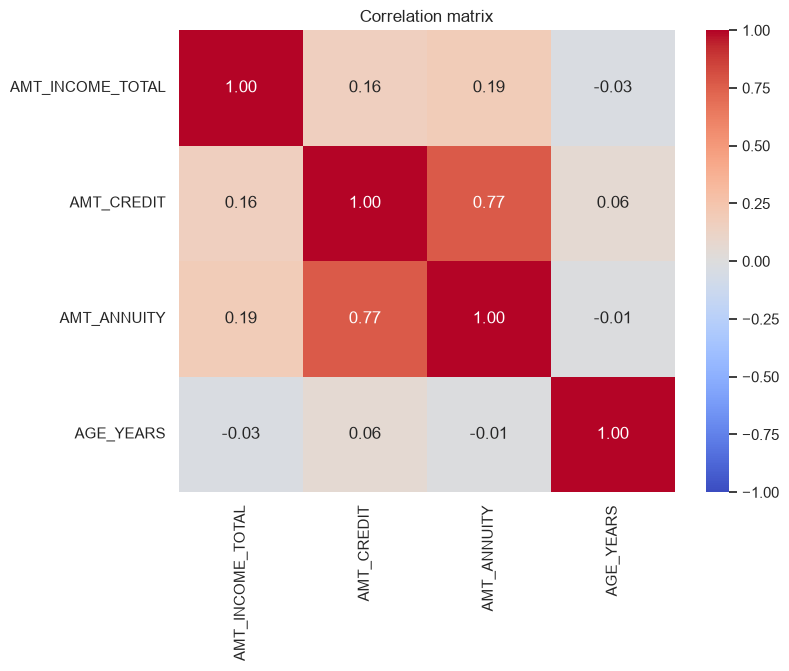

In [8]:
sns.kdeplot(data=df,x='AGE_YEARS',hue='TARGET',common_norm=False,fill=True)
plt.title('Age Distribution by Target')
plt.show()

numeric_cols = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AGE_YEARS']
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix,annot=True,fmt=".2f",cmap='coolwarm',vmin=-1,vmax=1)
plt.title('Correlation matrix')
plt.show()

Люди 25-40 лет чаще не попадают в дефолт,с ростом возраста дефолт падает
Силная положительная корреляия между суммой кредита и размером платежа


TypeError: all inputs must be Index